# 🎓 Student Performance Data Warehouse and Predictive Analysis

---

**Course:** Data Mining  
**Project Type:** Complete End-to-End Data Mining System  
**Dataset:** Student Performance Dataset  

---

## 1. Introduction

### 1.1 Project Overview

This project presents a comprehensive **Educational Data Mining (EDM)** system designed to analyze student academic performance, build a structured data warehouse, and apply machine learning classification techniques to predict student outcomes. The system follows a rigorous end-to-end data science pipeline, from raw data ingestion through feature engineering, OLAP analysis, predictive modeling, and visual dashboard generation.

### 1.2 Objectives

The primary objectives of this project are:

1. **Preprocessing & Feature Engineering:** Clean, transform, and enrich raw student performance data with synthetic yet realistic features.
2. **Data Warehouse Design:** Architect a Star Schema data warehouse with a central fact table and supporting dimension tables.
3. **OLAP Operations:** Simulate analytical operations including roll-up, drill-down, slice, and dice to support multidimensional analysis.
4. **Machine Learning Classification:** Train and evaluate Decision Tree and Naive Bayes classifiers to categorize students as *Excellent*, *Average*, or *At-Risk*.
5. **Visualization & Dashboards:** Generate professional data visualizations and an analytical dashboard.
6. **Data Export:** Export all artifacts including warehouse tables, processed datasets, trained models, and dashboard data.

### 1.3 Importance of Educational Data Mining

Educational Data Mining (EDM) is an emerging discipline that applies data mining and machine learning techniques to educational data with the goal of improving student outcomes and institutional effectiveness. Key benefits include:

- **Early Intervention:** Identifying at-risk students before academic failure occurs.
- **Personalized Learning:** Tailoring educational strategies based on individual performance patterns.
- **Institutional Decision-Making:** Enabling data-driven policy and curriculum design.
- **Resource Optimization:** Allocating tutoring and support where most needed.

### 1.4 Workflow Description

```
Raw CSV Data
    ↓
Data Loading & Inspection
    ↓
Preprocessing & Cleaning
    ↓
Feature Engineering
    ↓
Exploratory Data Analysis (EDA)
    ↓
Star Schema Design & Implementation (SQLite)
    ↓
OLAP Operations (Roll-up, Drill-down, Slice, Dice)
    ↓
Machine Learning (Decision Tree | Naive Bayes)
    ↓
Model Evaluation & Comparison
    ↓
Visual Dashboard
    ↓
Export: CSVs, Models, Dashboard Data
    ↓
Conclusion & Future Work
```

---
## 2. Import Libraries

In [5]:
# ============================================================
# SECTION 2: IMPORT LIBRARIES
# Import all required libraries for data processing,
# visualization, database operations, and machine learning.
# ============================================================

import os
import sqlite3
import pickle
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import joblib

# Scikit-learn: preprocessing
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score

# Scikit-learn: classifiers
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB

# Scikit-learn: evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Suppress non-critical warnings for cleaner output
warnings.filterwarnings('ignore')

# Set global random seed for reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Global plot styling
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({
    'figure.dpi': 120,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11
})

print("✅ All libraries imported successfully.")
print(f"   NumPy version    : {np.__version__}")
print(f"   Pandas version   : {pd.__version__}")
print(f"   Random Seed      : {RANDOM_SEED}")

✅ All libraries imported successfully.
   NumPy version    : 2.3.5
   Pandas version   : 2.3.3
   Random Seed      : 42


---
## 3. Data Loading

The dataset used in this project is the **Students Performance in Exams** dataset. It contains demographic and academic features for students. We load it from a CSV file and perform initial inspection.

In [6]:
df = pd.read_csv('data/StudentsPerformance.csv')

print("=" * 55)
print("  DATASET LOADED SUCCESSFULLY")
print("=" * 55)
print(f"  Source  : data/StudentsPerformance.csv")
print(f"  Rows    : {df.shape[0]}")
print(f"  Columns : {df.shape[1]}")
print("=" * 55)

  DATASET LOADED SUCCESSFULLY
  Source  : data/StudentsPerformance.csv
  Rows    : 1000
  Columns : 8


In [7]:
# --- 3.1 Display First Records ---
print("\n First 5 Records:")
df.head()


 First 5 Records:


,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group E,associate's degree,free/reduced,none,72.0,88.0,58.0
1,female,group B,bachelor's degree,free/reduced,none,63.0,81.0,65.0
2,male,group D,some college,standard,completed,75.0,69.0,56.0
3,female,group C,high school,standard,none,88.0,59.0,63.0
4,male,group A,some high school,standard,completed,61.0,78.0,40.0


In [8]:
# --- 3.2 Dataset Shape ---
print(f"Dataset Shape: {df.shape[0]} rows × {df.shape[1]} columns")

Dataset Shape: 1000 rows × 8 columns


In [9]:
# --- 3.3 Dataset Info ---
print("\n Dataset Info:")
df.info()


 Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   gender                       1000 non-null   object 
 1   race_ethnicity               1000 non-null   object 
 2   parental_level_of_education  1000 non-null   object 
 3   lunch                        1000 non-null   object 
 4   test_preparation_course      1000 non-null   object 
 5   math_score                   980 non-null    float64
 6   reading_score                980 non-null    float64
 7   writing_score                980 non-null    float64
dtypes: float64(3), object(5)
memory usage: 62.6+ KB


In [10]:
# --- 3.4 Statistical Summary ---
print("\n Statistical Summary:")
df.describe(include='all').round(2)


 Statistical Summary:


,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
count,1000,1000,1000,1000,1000,980.00,980.00,980.00
unique,2,5,6,2,2,NaN,NaN,NaN
top,female,group C,high school,standard,none,NaN,NaN,NaN
freq,504,322,185,668,663,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,65.21,68.89,66.97
std,NaN,NaN,NaN,NaN,NaN,14.58,13.82,13.59
min,NaN,NaN,NaN,NaN,NaN,16.00,27.00,25.00
25%,NaN,NaN,NaN,NaN,NaN,55.00,59.75,58.00
50%,NaN,NaN,NaN,NaN,NaN,65.00,69.00,67.00
75%,NaN,NaN,NaN,NaN,NaN,75.00,78.00,76.00


---
## 4. Data Preprocessing

Before any analysis or modeling, the dataset must be cleaned and validated. This section covers:
- Missing value detection and imputation
- Duplicate row removal
- Data type verification
- Outlier visualization using box plots

In [11]:
# ============================================================
# SECTION 4: DATA PREPROCESSING
# ============================================================

# --- 4.1 Missing Value Analysis ---
print("=" * 45)
print("  MISSING VALUE ANALYSIS")
print("=" * 45)

missing_counts = df.isnull().sum()
missing_pct    = (df.isnull().mean() * 100).round(2)

missing_df = pd.DataFrame({
    'Missing Count'     : missing_counts,
    'Missing Percent %' : missing_pct
})
print(missing_df[missing_df['Missing Count'] > 0])
print(f"\nTotal missing cells: {df.isnull().sum().sum()}")

  MISSING VALUE ANALYSIS
               Missing Count  Missing Percent %
math_score                20                2.0
reading_score             20                2.0
writing_score             20                2.0

Total missing cells: 60


In [12]:
# --- 4.2 Impute Missing Values ---
# Fill missing numeric scores with column median (robust to outliers)
for col in ['math_score', 'reading_score', 'writing_score']:
    median_val = df[col].median()
    df[col].fillna(median_val, inplace=True)
    print(f"  '{col}' missing values filled with median: {median_val:.1f}")

print(f"\nMissing values after imputation: {df.isnull().sum().sum()}")

  'math_score' missing values filled with median: 65.0
  'reading_score' missing values filled with median: 69.0
  'writing_score' missing values filled with median: 67.0

Missing values after imputation: 0


In [13]:
# --- 4.3 Duplicate Detection and Removal ---
n_duplicates = df.duplicated().sum()
print(f"Duplicate rows found: {n_duplicates}")
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
print(f"Dataset shape after deduplication: {df.shape}")

Duplicate rows found: 0
Dataset shape after deduplication: (1000, 8)


In [14]:
# --- 4.4 Data Type Verification ---
print("Column Data Types:")
print(df.dtypes)

Column Data Types:
gender                          object
race_ethnicity                  object
parental_level_of_education     object
lunch                           object
test_preparation_course         object
math_score                     float64
reading_score                  float64
writing_score                  float64
dtype: object


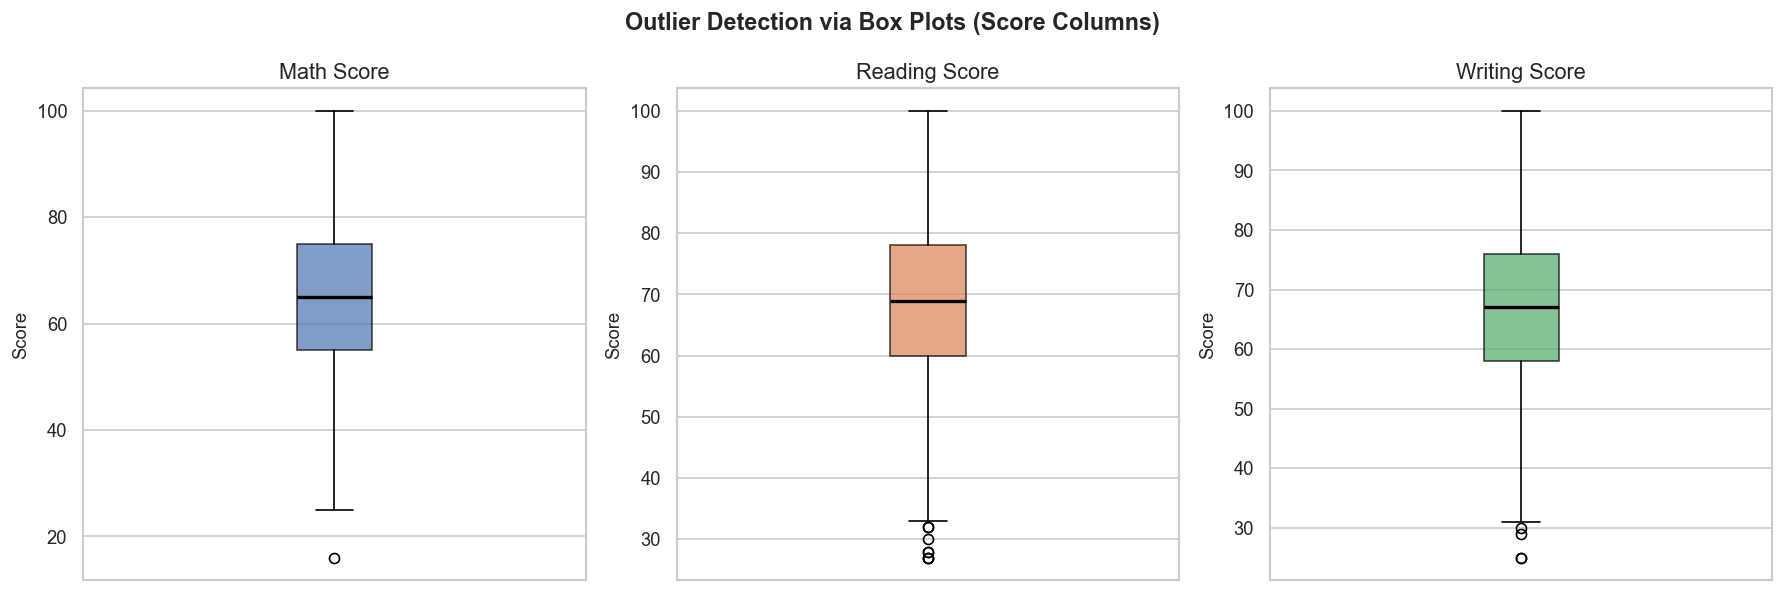

Outlier box plots generated.


In [15]:
# --- 4.5 Outlier Visualization ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Outlier Detection via Box Plots (Score Columns)', fontsize=14, fontweight='bold')

score_cols  = ['math_score', 'reading_score', 'writing_score']
score_colors = ['#4C72B0', '#DD8452', '#55A868']

for ax, col, color in zip(axes, score_cols, score_colors):
    ax.boxplot(df[col], patch_artist=True,
               boxprops=dict(facecolor=color, alpha=0.7),
               medianprops=dict(color='black', linewidth=2))
    ax.set_title(col.replace('_', ' ').title())
    ax.set_ylabel('Score')
    ax.set_xticks([])

plt.tight_layout()
plt.savefig('data/outlier_boxplots.png', bbox_inches='tight')
plt.show()
print("Outlier box plots generated.")

In [16]:
# --- 4.6 Clip Extreme Outliers ---
# Clamp scores to valid range [0, 100]; fillna again after clip to be safe
for col in score_cols:
    df[col] = df[col].clip(0, 100).round()
    df[col] = df[col].fillna(df[col].median()).astype(int)

print("Scores clipped to valid range [0, 100].")
print("\nCleaned Score Statistics:")
print(df[score_cols].describe().round(2))

Scores clipped to valid range [0, 100].

Cleaned Score Statistics:
       math_score  reading_score  writing_score
count     1000.00        1000.00        1000.00
mean        65.21          68.89          66.97
std         14.43          13.68          13.45
min         16.00          27.00          25.00
25%         55.00          60.00          58.00
50%         65.00          69.00          67.00
75%         75.00          78.00          76.00
max        100.00         100.00         100.00


---
## 5. Feature Engineering

This section enriches the dataset with additional synthetic features that capture realistic educational contexts. Features are generated such that their values are logically consistent — for example, higher attendance and study hours are positively correlated with academic performance.

In [17]:
# ============================================================
# SECTION 5: FEATURE ENGINEERING
# Generate realistic synthetic columns and compute
# derived features including the target label 'final_status'.
# ============================================================

np.random.seed(RANDOM_SEED)
n = len(df)

# --- 5.1 Student ID ---
df['student_id'] = ['STU' + str(i+1).zfill(4) for i in range(n)]

# --- 5.2 Compute Average Score (from existing scores) ---
df['average_score'] = (
    df['math_score'] + df['reading_score'] + df['writing_score']
) / 3
df['average_score'] = df['average_score'].round(2)

# --- 5.3 Attendance ---
# Higher average score → higher attendance tendency
# Base attendance drawn from normal, boosted by score percentile
score_pct   = (df['average_score'] - df['average_score'].min()) / \
              (df['average_score'].max() - df['average_score'].min())
attendance  = (55 + score_pct * 40 + np.random.normal(0, 5, n)).clip(50, 100)
df['attendance'] = attendance.round(1)

# --- 5.4 Study Hours Per Week ---
# Range 1–20 hrs; positively correlated with performance
study_hours = (2 + score_pct * 16 + np.random.normal(0, 2, n)).clip(1, 20)
df['study_hours'] = study_hours.round(1)

# --- 5.5 Semester ---
df['semester'] = np.random.choice(
    ['Spring 2023', 'Fall 2023', 'Spring 2024', 'Fall 2024'],
    n,
    p=[0.25, 0.25, 0.25, 0.25]
)

# --- 5.6 Department ---
departments = ['Science', 'Arts', 'Commerce', 'Engineering', 'Humanities']
df['department'] = np.random.choice(departments, n)

# --- 5.7 Course Name (linked to department) ---
dept_courses = {
    'Science'     : ['Biology', 'Chemistry', 'Physics'],
    'Arts'        : ['Literature', 'Fine Arts', 'Music'],
    'Commerce'    : ['Accounting', 'Economics', 'Business'],
    'Engineering' : ['Mathematics', 'Computer Science', 'Electronics'],
    'Humanities'  : ['History', 'Philosophy', 'Geography']
}

df['course_name'] = df['department'].apply(
    lambda d: np.random.choice(dept_courses[d])
)

# --- 5.8 Final Status (Target Label) ---
# Classification rules based on average_score:
#   >= 85  → Excellent
#   < 50   → At-Risk
#   else   → Average
def classify_status(score):
    if score >= 85:
        return 'Excellent'
    elif score < 50:
        return 'At-Risk'
    else:
        return 'Average'

df['final_status'] = df['average_score'].apply(classify_status)

# --- Summary ---
print("=" * 50)
print("  FEATURE ENGINEERING COMPLETE")
print("=" * 50)
print(f"  Total columns after engineering: {df.shape[1]}")
print(f"  Total records                  : {df.shape[0]}")

print("\n📊 Final Status Distribution:")
print(df['final_status'].value_counts().to_frame())

print("\n📋 Sample of Engineered Dataset:")
df[['student_id', 'department', 'course_name', 'semester',
    'attendance', 'study_hours', 'average_score', 'final_status']].head()

  FEATURE ENGINEERING COMPLETE
  Total columns after engineering: 16
  Total records                  : 1000

📊 Final Status Distribution:
              count
final_status       
Average         971
At-Risk          17
Excellent        12

📋 Sample of Engineered Dataset:


,student_id,department,course_name,semester,attendance,study_hours,average_score,final_status
0,STU0001,Commerce,Business,Fall 2023,82.4,14.8,72.67,Average
1,STU0002,Engineering,Electronics,Spring 2023,76.5,12.7,69.67,Average
2,STU0003,Humanities,History,Fall 2023,77.8,9.9,66.67,Average
3,STU0004,Arts,Music,Spring 2023,85.1,9.7,70.00,Average
4,STU0005,Commerce,Business,Fall 2024,67.2,8.7,59.67,Average


---
## 6. Exploratory Data Analysis (EDA)

EDA is performed to understand the underlying structure, distributions, and relationships within the dataset. A variety of visualizations are generated to gain insights across demographic, behavioral, and academic dimensions.

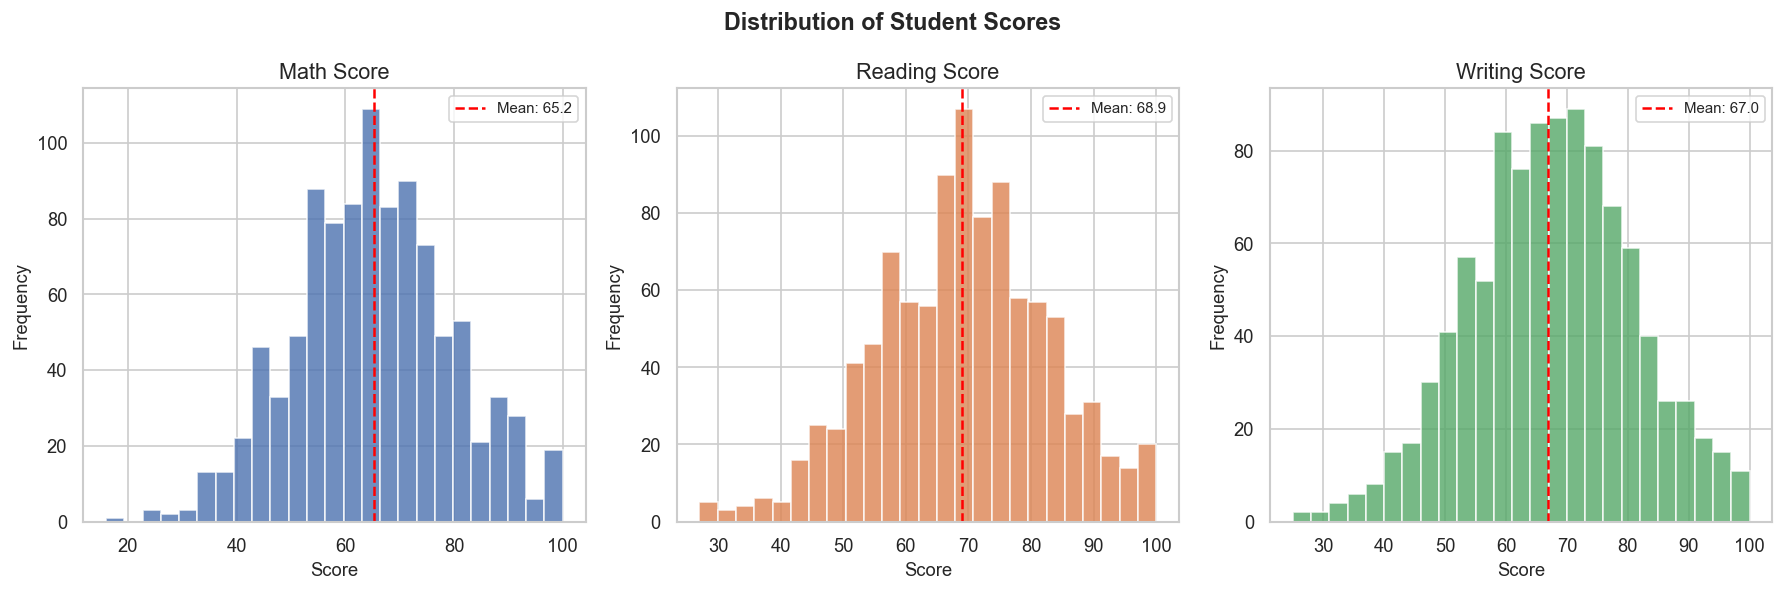

In [18]:
# ============================================================
# SECTION 6: EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================

# --- 6.1 Score Distribution Histograms ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Distribution of Student Scores', fontsize=14, fontweight='bold')

for ax, col, color in zip(axes, score_cols, ['#4C72B0', '#DD8452', '#55A868']):
    ax.hist(df[col], bins=25, color=color, alpha=0.8, edgecolor='white')
    ax.axvline(df[col].mean(), color='red', linestyle='--', linewidth=1.5,
               label=f'Mean: {df[col].mean():.1f}')
    ax.set_title(col.replace('_', ' ').title())
    ax.set_xlabel('Score')
    ax.set_ylabel('Frequency')
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig('data/score_distributions.png', bbox_inches='tight')
plt.show()

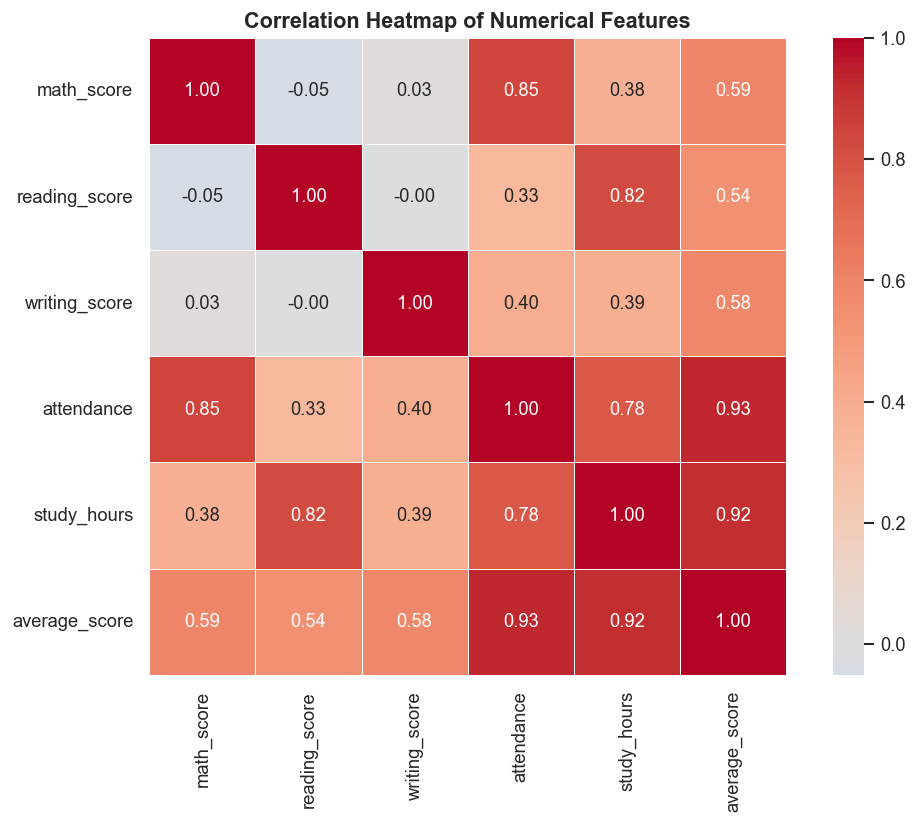

In [19]:
# --- 6.2 Correlation Heatmap ---
fig, ax = plt.subplots(figsize=(9, 7))

numeric_cols = ['math_score', 'reading_score', 'writing_score',
                'attendance', 'study_hours', 'average_score']
corr_matrix  = df[numeric_cols].corr()

sns.heatmap(
    corr_matrix,
    annot=True, fmt='.2f',
    cmap='coolwarm', center=0,
    square=True, linewidths=0.5,
    ax=ax
)
ax.set_title('Correlation Heatmap of Numerical Features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('data/correlation_heatmap.png', bbox_inches='tight')
plt.show()

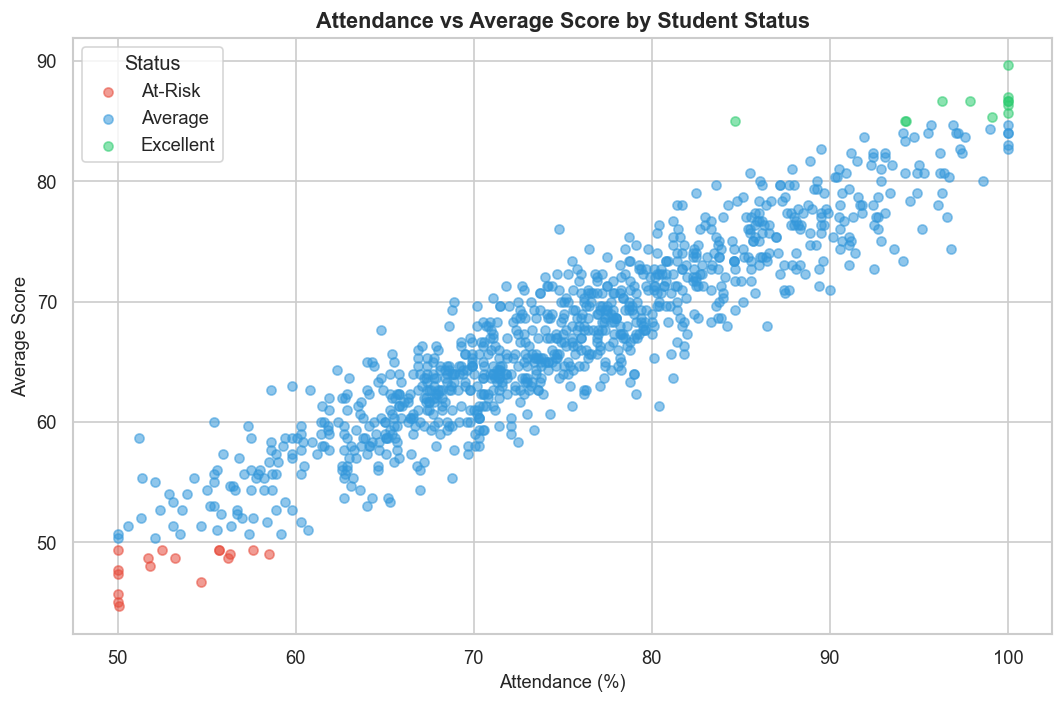

In [20]:
# --- 6.3 Attendance vs Average Score ---
fig, ax = plt.subplots(figsize=(9, 6))

status_colors = {'Excellent': '#2ecc71', 'Average': '#3498db', 'At-Risk': '#e74c3c'}

for status, grp in df.groupby('final_status'):
    ax.scatter(
        grp['attendance'], grp['average_score'],
        label=status, alpha=0.55, s=30,
        color=status_colors[status]
    )

ax.set_xlabel('Attendance (%)')
ax.set_ylabel('Average Score')
ax.set_title('Attendance vs Average Score by Student Status', fontweight='bold')
ax.legend(title='Status')
plt.tight_layout()
plt.savefig('data/attendance_vs_score.png', bbox_inches='tight')
plt.show()

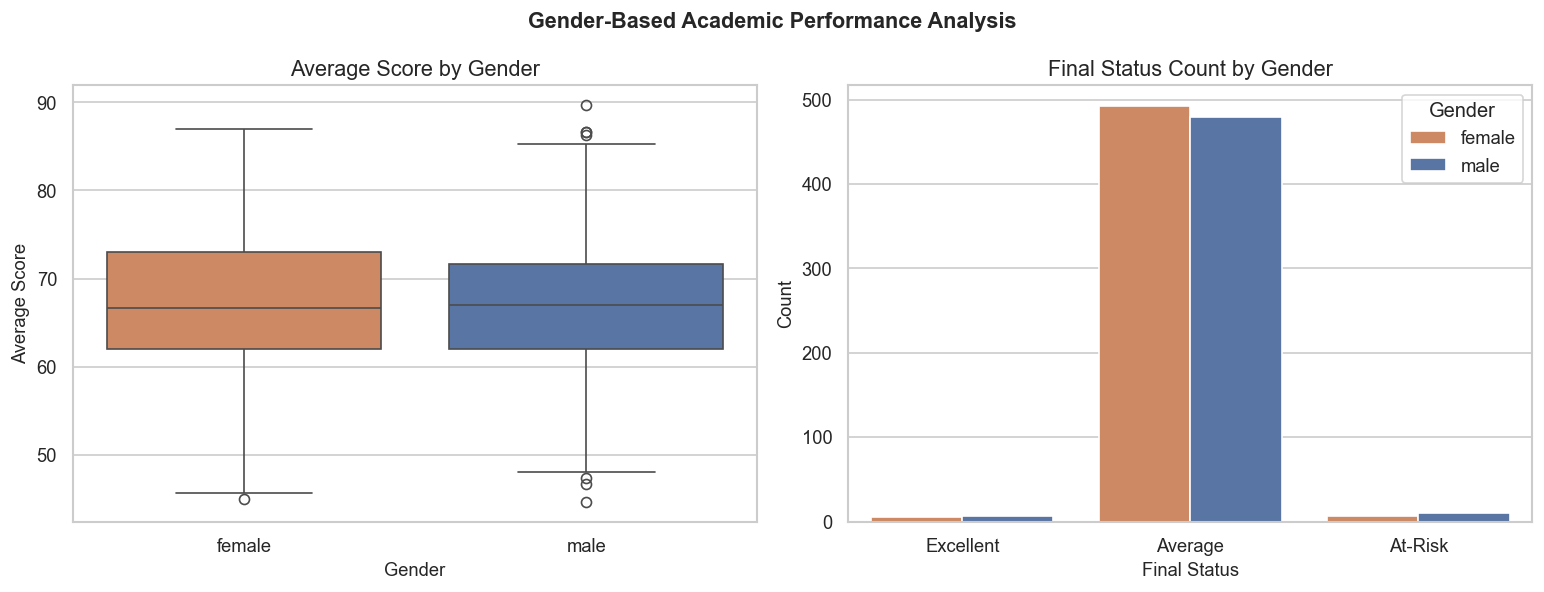

In [21]:
# --- 6.4 Gender Comparison ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Gender-Based Academic Performance Analysis', fontsize=13, fontweight='bold')

# Box plot: average score by gender
sns.boxplot(
    data=df, x='gender', y='average_score',
    palette={'male': '#4C72B0', 'female': '#DD8452'},
    ax=axes[0]
)
axes[0].set_title('Average Score by Gender')
axes[0].set_xlabel('Gender')
axes[0].set_ylabel('Average Score')

# Count plot: final status by gender
sns.countplot(
    data=df, x='final_status', hue='gender',
    palette={'male': '#4C72B0', 'female': '#DD8452'},
    order=['Excellent', 'Average', 'At-Risk'],
    ax=axes[1]
)
axes[1].set_title('Final Status Count by Gender')
axes[1].set_xlabel('Final Status')
axes[1].set_ylabel('Count')
axes[1].legend(title='Gender')

plt.tight_layout()
plt.savefig('data/gender_comparison.png', bbox_inches='tight')
plt.show()

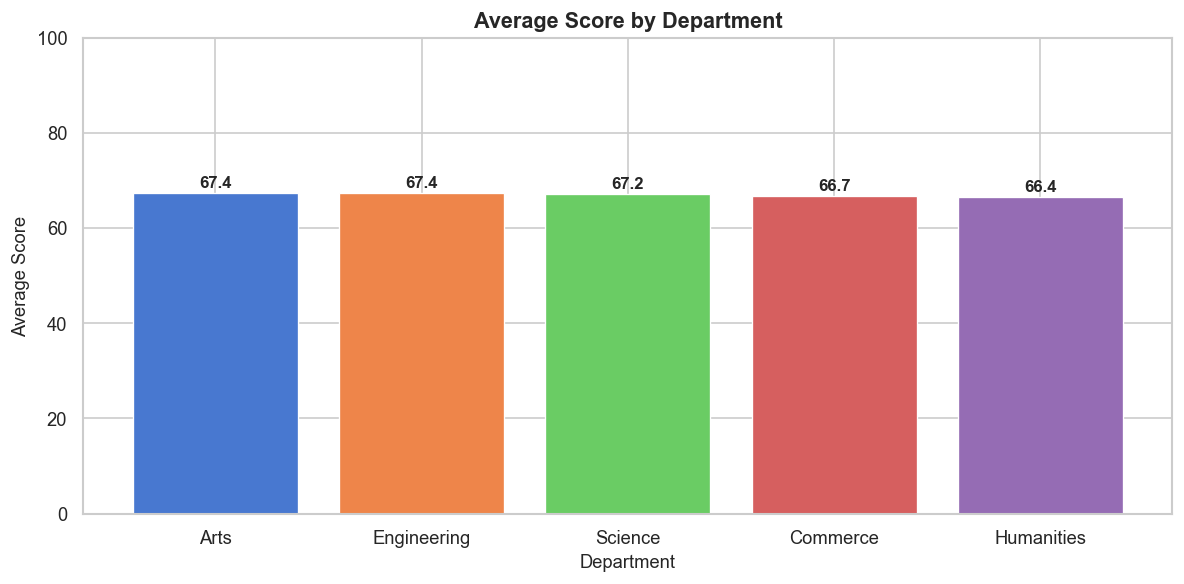

In [22]:
# --- 6.5 Department Performance Comparison ---
dept_avg = df.groupby('department')['average_score'].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(
    dept_avg.index, dept_avg.values,
    color=sns.color_palette('muted', len(dept_avg)),
    edgecolor='white', linewidth=0.8
)

# Annotate bars with values
for bar, val in zip(bars, dept_avg.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f'{val:.1f}',
        ha='center', va='bottom', fontsize=10, fontweight='bold'
    )

ax.set_title('Average Score by Department', fontsize=13, fontweight='bold')
ax.set_xlabel('Department')
ax.set_ylabel('Average Score')
ax.set_ylim(0, 100)
plt.tight_layout()
plt.savefig('data/department_performance.png', bbox_inches='tight')
plt.show()

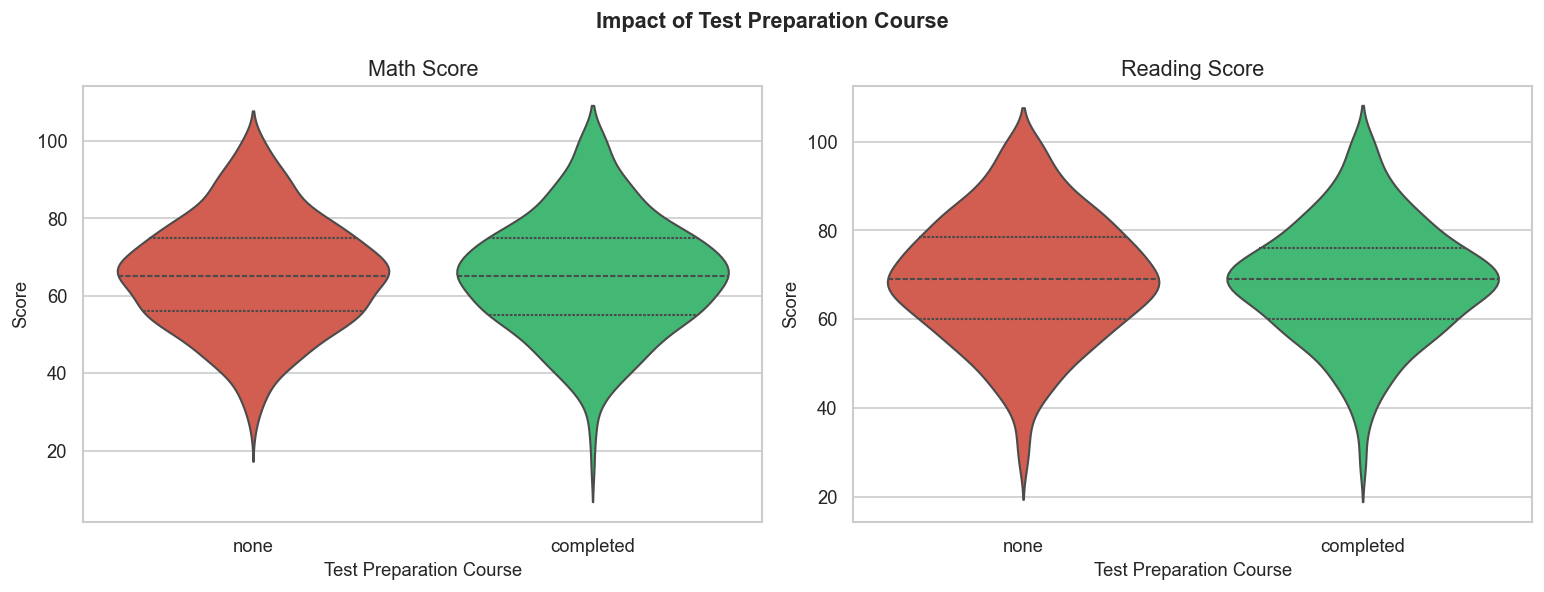

In [23]:
# --- 6.6 Test Preparation Course Impact ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Impact of Test Preparation Course', fontsize=13, fontweight='bold')

prep_palette = {'completed': '#2ecc71', 'none': '#e74c3c'}

for ax, score in zip(axes, ['math_score', 'reading_score']):
    sns.violinplot(
        data=df, x='test_preparation_course', y=score,
        palette=prep_palette, ax=ax, inner='quartile'
    )
    ax.set_title(score.replace('_', ' ').title())
    ax.set_xlabel('Test Preparation Course')
    ax.set_ylabel('Score')

plt.tight_layout()
plt.savefig('data/prep_course_impact.png', bbox_inches='tight')
plt.show()

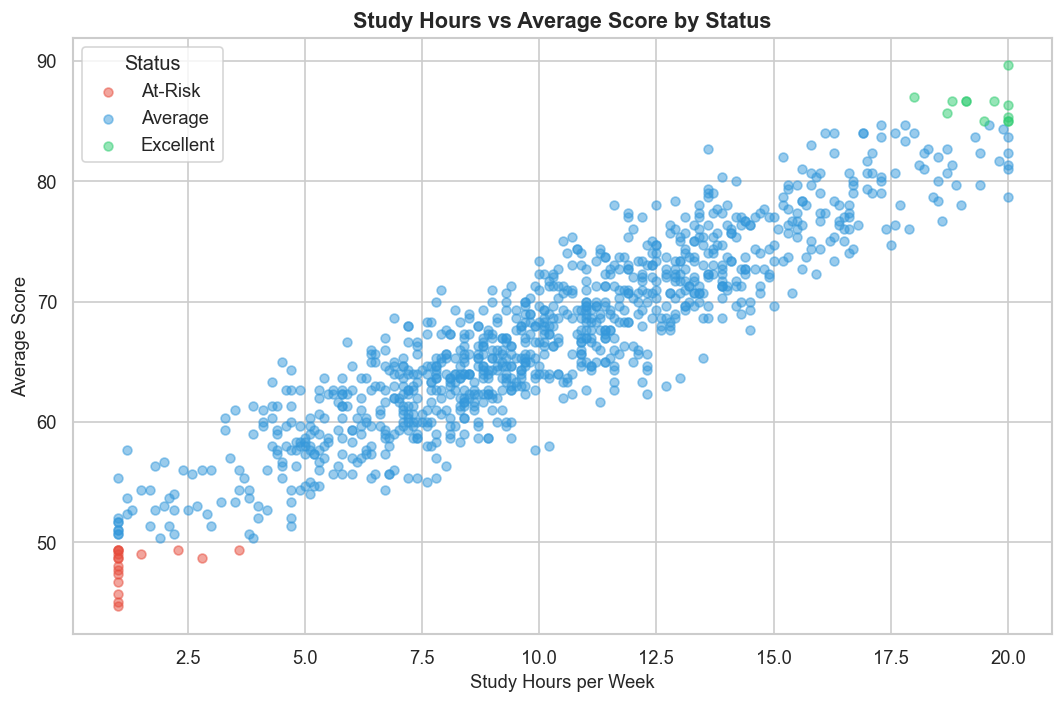

In [24]:
# --- 6.7 Study Hours vs Average Score ---
fig, ax = plt.subplots(figsize=(9, 6))

for status, grp in df.groupby('final_status'):
    ax.scatter(
        grp['study_hours'], grp['average_score'],
        label=status, alpha=0.5, s=28,
        color=status_colors[status]
    )

ax.set_xlabel('Study Hours per Week')
ax.set_ylabel('Average Score')
ax.set_title('Study Hours vs Average Score by Status', fontweight='bold')
ax.legend(title='Status')
plt.tight_layout()
plt.savefig('data/study_hours_vs_score.png', bbox_inches='tight')
plt.show()

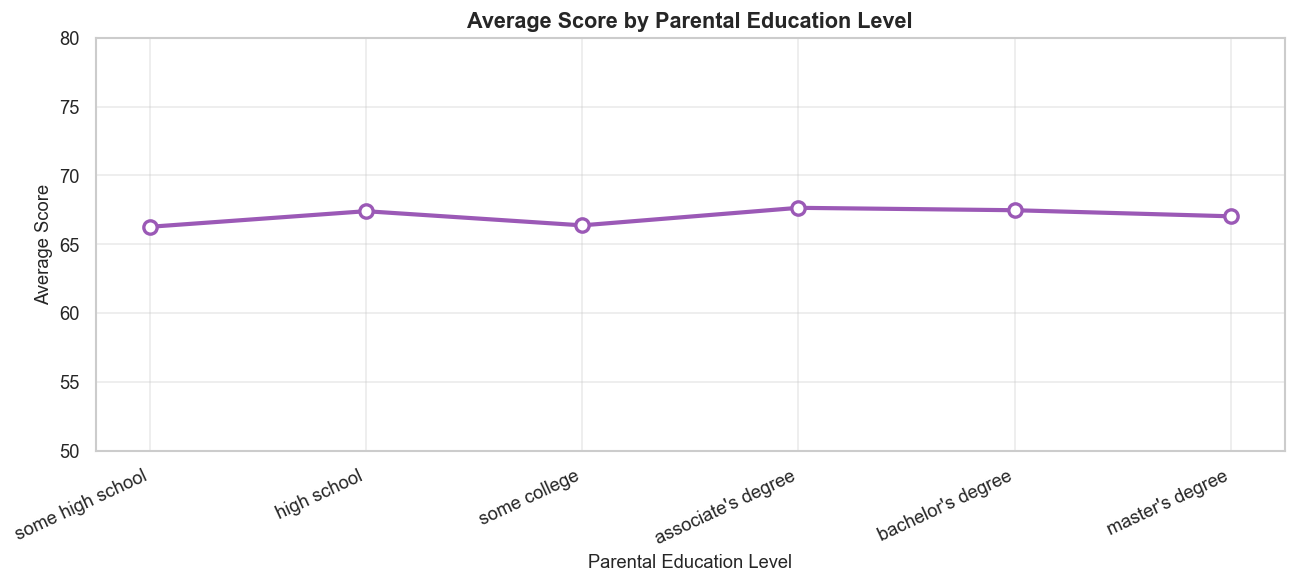

In [25]:
# --- 6.8 Parental Education vs Average Score ---
edu_order = [
    "some high school", "high school",
    "some college", "associate's degree",
    "bachelor's degree", "master's degree"
]

edu_avg = df.groupby('parental_level_of_education')['average_score'].mean()
edu_avg = edu_avg.reindex(edu_order)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(edu_avg.index, edu_avg.values, marker='o', linewidth=2.5,
        color='#9B59B6', markersize=8, markerfacecolor='white', markeredgewidth=2)

ax.set_title('Average Score by Parental Education Level', fontsize=13, fontweight='bold')
ax.set_xlabel('Parental Education Level')
ax.set_ylabel('Average Score')
ax.set_xticklabels(edu_order, rotation=25, ha='right')
ax.set_ylim(50, 80)
ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig('data/parental_edu_score.png', bbox_inches='tight')
plt.show()

---
## 7. Star Schema Design

### 7.1 Data Warehouse Architecture

A **Star Schema** is selected as the data warehouse design pattern. In a star schema, a central **Fact Table** stores quantitative measurements (scores, attendance, study hours), while surrounding **Dimension Tables** contain descriptive attributes. This design optimizes OLAP query performance.

### 7.2 Schema Overview

```
                    ┌─────────────────┐
                    │   Dim_Student   │
                    │  (student_id,   │
                    │  gender, race,  │
                    │  parental_edu,  │
                    │  lunch, prep)   │
                    └────────┬────────┘
                             │
┌──────────────┐    ┌────────▼──────────────────┐    ┌────────────────┐
│   Dim_Time   │    │  Fact_Student_Performance  │    │ Dim_Department │
│  (time_id,   ├────►   (fact_id, student_id,   ◄────┤  (dept_id,     │
│   semester,  │    │    time_id, dept_id,       │    │   dept_name)   │
│   year)      │    │    course_id, math_score,  │    └────────────────┘
└──────────────┘    │    reading_score,           │
                    │    writing_score,            │    ┌────────────────┐
                    │    average_score,            ◄────┤   Dim_Course   │
                    │    attendance,               │    │  (course_id,   │
                    │    study_hours,              │    │   course_name, │
                    │    final_status)             │    │   dept_id)     │
                    └─────────────────────────────┘    └────────────────┘
```

### 7.3 Table Descriptions

| Table | Type | Description |
|-------|------|-------------|
| `Fact_Student_Performance` | Fact | Central table storing all measurable metrics per student per semester |
| `Dim_Student` | Dimension | Student demographic and background attributes |
| `Dim_Time` | Dimension | Time dimension capturing semester and academic year |
| `Dim_Department` | Dimension | Academic department information |
| `Dim_Course` | Dimension | Course catalog linked to departments |

### 7.4 ERD-Style Key Relationships

- `Fact_Student_Performance.student_id` → `Dim_Student.student_id` *(Many-to-One)*
- `Fact_Student_Performance.time_id` → `Dim_Time.time_id` *(Many-to-One)*
- `Fact_Student_Performance.dept_id` → `Dim_Department.dept_id` *(Many-to-One)*
- `Fact_Student_Performance.course_id` → `Dim_Course.course_id` *(Many-to-One)*

---
## 8. Data Warehouse Implementation (SQLite)

The Star Schema is implemented using Python's built-in `sqlite3` library. All tables are created, populated, and verified within the notebook.

In [26]:
# ============================================================
# SECTION 8: DATA WAREHOUSE IMPLEMENTATION
# Build Star Schema in SQLite and insert data.
# ============================================================

# --- 8.1 Build Dimension Tables ---

# Dim_Student
dim_student = df[[
    'student_id', 'gender', 'race_ethnicity',
    'parental_level_of_education', 'lunch',
    'test_preparation_course'
]].drop_duplicates(subset='student_id').reset_index(drop=True)
dim_student.rename(columns={
    'race_ethnicity'              : 'race',
    'parental_level_of_education' : 'parental_edu',
    'test_preparation_course'     : 'prep_course'
}, inplace=True)

# Dim_Time
semesters = df['semester'].unique()
dim_time = pd.DataFrame({
    'time_id'  : range(1, len(semesters) + 1),
    'semester' : semesters,
    'year'     : [int(s.split()[-1]) for s in semesters],
    'season'   : [s.split()[0] for s in semesters]
})

# Dim_Department
dept_list = df['department'].unique()
dim_department = pd.DataFrame({
    'dept_id'  : range(1, len(dept_list) + 1),
    'dept_name': dept_list
})

# Dim_Course
course_df = df[['course_name', 'department']].drop_duplicates().reset_index(drop=True)
course_df = course_df.merge(dim_department, left_on='department', right_on='dept_name', how='left')
dim_course = pd.DataFrame({
    'course_id'  : range(1, len(course_df) + 1),
    'course_name': course_df['course_name'],
    'dept_id'    : course_df['dept_id']
})

# --- 8.2 Build Fact Table ---
# Merge foreign keys into the fact table
fact = df.copy()
fact = fact.merge(dim_time[['time_id', 'semester']], on='semester', how='left')
fact = fact.merge(dim_department.rename(columns={'dept_name': 'department'}),
                  on='department', how='left')
fact = fact.merge(
    dim_course[['course_id', 'course_name']],
    on='course_name', how='left'
)

fact_cols = [
    'student_id', 'time_id', 'dept_id', 'course_id',
    'math_score', 'reading_score', 'writing_score',
    'average_score', 'attendance', 'study_hours', 'final_status'
]
fact_table = fact[fact_cols].copy().reset_index(drop=True)
fact_table.insert(0, 'fact_id', range(1, len(fact_table) + 1))

print(" Dimension and Fact tables created.")
print(f"   Dim_Student           : {dim_student.shape}")
print(f"   Dim_Time              : {dim_time.shape}")
print(f"   Dim_Department        : {dim_department.shape}")
print(f"   Dim_Course            : {dim_course.shape}")
print(f"   Fact_Student_Perf     : {fact_table.shape}")

 Dimension and Fact tables created.
   Dim_Student           : (1000, 6)
   Dim_Time              : (4, 4)
   Dim_Department        : (5, 2)
   Dim_Course            : (15, 3)
   Fact_Student_Perf     : (1000, 12)


In [27]:
# --- 8.3 Create SQLite Database and Populate Tables ---

DB_PATH = 'data/student_warehouse.db'
conn = sqlite3.connect(DB_PATH)
cur  = conn.cursor()

# Drop tables if they exist (for clean re-runs)
for tbl in ['Fact_Student_Performance', 'Dim_Student',
            'Dim_Time', 'Dim_Department', 'Dim_Course']:
    cur.execute(f'DROP TABLE IF EXISTS {tbl}')

# Create tables using DDL
cur.executescript("""
CREATE TABLE Dim_Student (
    student_id   TEXT PRIMARY KEY,
    gender       TEXT,
    race         TEXT,
    parental_edu TEXT,
    lunch        TEXT,
    prep_course  TEXT
);

CREATE TABLE Dim_Time (
    time_id  INTEGER PRIMARY KEY,
    semester TEXT,
    year     INTEGER,
    season   TEXT
);

CREATE TABLE Dim_Department (
    dept_id   INTEGER PRIMARY KEY,
    dept_name TEXT
);

CREATE TABLE Dim_Course (
    course_id   INTEGER PRIMARY KEY,
    course_name TEXT,
    dept_id     INTEGER,
    FOREIGN KEY (dept_id) REFERENCES Dim_Department(dept_id)
);

CREATE TABLE Fact_Student_Performance (
    fact_id       INTEGER PRIMARY KEY,
    student_id    TEXT,
    time_id       INTEGER,
    dept_id       INTEGER,
    course_id     INTEGER,
    math_score    REAL,
    reading_score REAL,
    writing_score REAL,
    average_score REAL,
    attendance    REAL,
    study_hours   REAL,
    final_status  TEXT,
    FOREIGN KEY (student_id) REFERENCES Dim_Student(student_id),
    FOREIGN KEY (time_id)    REFERENCES Dim_Time(time_id),
    FOREIGN KEY (dept_id)    REFERENCES Dim_Department(dept_id),
    FOREIGN KEY (course_id)  REFERENCES Dim_Course(course_id)
);
""")

# Insert data from DataFrames
dim_student.to_sql('Dim_Student', conn, if_exists='append', index=False)
dim_time.to_sql('Dim_Time', conn, if_exists='append', index=False)
dim_department.to_sql('Dim_Department', conn, if_exists='append', index=False)
dim_course.to_sql('Dim_Course', conn, if_exists='append', index=False)
fact_table.to_sql('Fact_Student_Performance', conn, if_exists='append', index=False)
conn.commit()

print(f" SQLite Data Warehouse created at: {DB_PATH}")

# Verify row counts
for tbl in ['Dim_Student', 'Dim_Time', 'Dim_Department',
            'Dim_Course', 'Fact_Student_Performance']:
    count = cur.execute(f'SELECT COUNT(*) FROM {tbl}').fetchone()[0]
    print(f"   {tbl:<30}: {count} rows")

 SQLite Data Warehouse created at: data/student_warehouse.db
   Dim_Student                   : 1000 rows
   Dim_Time                      : 4 rows
   Dim_Department                : 5 rows
   Dim_Course                    : 15 rows
   Fact_Student_Performance      : 1000 rows


In [28]:
# --- 8.4 Example SQL Queries ---

print("\n" + "=" * 55)
print("  SQL QUERY 1: Top 10 Students by Average Score")
print("=" * 55)
q1 = pd.read_sql_query("""
    SELECT f.student_id,
           s.gender,
           d.dept_name AS department,
           f.average_score,
           f.final_status
    FROM   Fact_Student_Performance f
    JOIN   Dim_Student   s ON f.student_id = s.student_id
    JOIN   Dim_Department d ON f.dept_id    = d.dept_id
    ORDER  BY f.average_score DESC
    LIMIT  10
""", conn)
print(q1.to_string(index=False))

print("\n" + "=" * 55)
print("  SQL QUERY 2: Department Average Scores")
print("=" * 55)
q2 = pd.read_sql_query("""
    SELECT d.dept_name AS Department,
           ROUND(AVG(f.math_score),2)    AS Avg_Math,
           ROUND(AVG(f.reading_score),2) AS Avg_Reading,
           ROUND(AVG(f.writing_score),2) AS Avg_Writing,
           ROUND(AVG(f.average_score),2) AS Avg_Overall
    FROM   Fact_Student_Performance f
    JOIN   Dim_Department d ON f.dept_id = d.dept_id
    GROUP  BY d.dept_name
    ORDER  BY Avg_Overall DESC
""", conn)
print(q2.to_string(index=False))

print("\n" + "=" * 55)
print("  SQL QUERY 3: Status Counts per Semester")
print("=" * 55)
q3 = pd.read_sql_query("""
    SELECT t.semester,
           f.final_status,
           COUNT(*) AS student_count
    FROM   Fact_Student_Performance f
    JOIN   Dim_Time t ON f.time_id = t.time_id
    GROUP  BY t.semester, f.final_status
    ORDER  BY t.semester, f.final_status
""", conn)
print(q3.to_string(index=False))


  SQL QUERY 1: Top 10 Students by Average Score
student_id gender  department  average_score final_status
   STU0813   male Engineering          89.67    Excellent
   STU0324 female     Science          87.00    Excellent
   STU0121 female     Science          86.67    Excellent
   STU0739   male  Humanities          86.67    Excellent
   STU0929   male        Arts          86.67    Excellent
   STU0956 female        Arts          86.67    Excellent
   STU0210   male     Science          86.33    Excellent
   STU0422 female Engineering          85.67    Excellent
   STU0625   male    Commerce          85.33    Excellent
   STU0036   male Engineering          85.00    Excellent

  SQL QUERY 2: Department Average Scores
 Department  Avg_Math  Avg_Reading  Avg_Writing  Avg_Overall
Engineering     65.56        68.63        67.90        67.36
       Arts     66.05        68.95        67.09        67.36
    Science     66.18        68.17        67.37        67.24
   Commerce     64.82      

---
## 9. OLAP Operations

**Online Analytical Processing (OLAP)** allows multidimensional analysis of business data. The four core operations are:

| Operation | Description |
|-----------|-------------|
| **Roll-Up** | Aggregates data to a higher level of hierarchy (e.g., course → department) |
| **Drill-Down** | Navigates to finer granularity (e.g., department → course → student) |
| **Slice** | Selects a single dimension value, reducing dimensionality |
| **Dice** | Selects sub-cubes by filtering on two or more dimension values |

In [29]:
# ============================================================
# SECTION 9: OLAP OPERATIONS
# ============================================================

# --- 9.1 ROLL-UP: Course → Department ---
# Aggregates individual course scores up to department level
print("ROLL-UP: Average Score — Course Level → Department Level")
print("-" * 58)

rollup_course = pd.read_sql_query("""
    SELECT c.course_name,
           d.dept_name,
           ROUND(AVG(f.average_score), 2) AS avg_score,
           COUNT(*)                        AS n_students
    FROM   Fact_Student_Performance f
    JOIN   Dim_Course     c ON f.course_id = c.course_id
    JOIN   Dim_Department d ON f.dept_id   = d.dept_id
    GROUP  BY c.course_name, d.dept_name
    ORDER  BY d.dept_name, avg_score DESC
""", conn)

rollup_dept = rollup_course.groupby('dept_name')['avg_score'].mean().round(2)
print("\nCourse-Level (Fine Grain):")
print(rollup_course.to_string(index=False))
print("\nDepartment-Level (Rolled-Up):")
print(rollup_dept.to_frame().to_string())

ROLL-UP: Average Score — Course Level → Department Level
----------------------------------------------------------

Course-Level (Fine Grain):
     course_name   dept_name  avg_score  n_students
      Literature        Arts      68.43          64
           Music        Arts      67.83          60
       Fine Arts        Arts      66.05          74
       Economics    Commerce      67.26          66
        Business    Commerce      66.68          74
      Accounting    Commerce      66.12          59
     Mathematics Engineering      67.68          76
     Electronics Engineering      67.56          75
Computer Science Engineering      66.75          65
       Geography  Humanities      66.50          65
         History  Humanities      66.47          75
      Philosophy  Humanities      66.35          60
       Chemistry     Science      68.02          66
         Biology     Science      66.90          59
         Physics     Science      66.72          62

Department-Level (Rolle

In [30]:
# --- 9.2 DRILL-DOWN: Department → Course → Student ---
print(" DRILL-DOWN: Engineering Department → Courses → Students")
print("-" * 60)

drilldown = pd.read_sql_query("""
    SELECT d.dept_name,
           c.course_name,
           f.student_id,
           f.average_score,
           f.final_status
    FROM   Fact_Student_Performance f
    JOIN   Dim_Department d ON f.dept_id   = d.dept_id
    JOIN   Dim_Course     c ON f.course_id = c.course_id
    WHERE  d.dept_name = 'Engineering'
    ORDER  BY c.course_name, f.average_score DESC
    LIMIT  15
""", conn)
print(drilldown.to_string(index=False))

 DRILL-DOWN: Engineering Department → Courses → Students
------------------------------------------------------------
  dept_name      course_name student_id  average_score final_status
Engineering Computer Science    STU0813          89.67    Excellent
Engineering Computer Science    STU0839          82.00      Average
Engineering Computer Science    STU0721          79.67      Average
Engineering Computer Science    STU0414          78.67      Average
Engineering Computer Science    STU0507          78.00      Average
Engineering Computer Science    STU0146          77.67      Average
Engineering Computer Science    STU0297          77.33      Average
Engineering Computer Science    STU0553          77.33      Average
Engineering Computer Science    STU0580          77.00      Average
Engineering Computer Science    STU0895          75.67      Average
Engineering Computer Science    STU0520          75.00      Average
Engineering Computer Science    STU0660          74.00      Averag

In [31]:
# --- 9.3 SLICE: Select Fall 2024 semester only ---
print("SLICE: Performance in 'Fall 2024' Semester")
print("-" * 50)

slice_result = pd.read_sql_query("""
    SELECT t.semester,
           d.dept_name,
           ROUND(AVG(f.average_score), 2) AS avg_score,
           COUNT(*) AS n_students
    FROM   Fact_Student_Performance f
    JOIN   Dim_Time       t ON f.time_id = t.time_id
    JOIN   Dim_Department d ON f.dept_id = d.dept_id
    WHERE  t.semester = 'Fall 2024'
    GROUP  BY d.dept_name
    ORDER  BY avg_score DESC
""", conn)
print(slice_result.to_string(index=False))

SLICE: Performance in 'Fall 2024' Semester
--------------------------------------------------
 semester   dept_name  avg_score  n_students
Fall 2024        Arts      68.37          52
Fall 2024 Engineering      68.29          51
Fall 2024     Science      68.19          55
Fall 2024  Humanities      67.42          43
Fall 2024    Commerce      66.29          45


In [32]:
# --- 9.4 DICE: Female Excellent students in Science or Engineering ---
print("DICE: Excellent Female Students in Science or Engineering")
print("-" * 60)

dice_result = pd.read_sql_query("""
    SELECT f.student_id,
           s.gender,
           d.dept_name,
           t.semester,
           f.average_score,
           f.final_status
    FROM   Fact_Student_Performance f
    JOIN   Dim_Student   s ON f.student_id = s.student_id
    JOIN   Dim_Department d ON f.dept_id   = d.dept_id
    JOIN   Dim_Time       t ON f.time_id   = t.time_id
    WHERE  s.gender      = 'female'
    AND    f.final_status = 'Excellent'
    AND    d.dept_name   IN ('Science', 'Engineering')
    ORDER  BY f.average_score DESC
    LIMIT  12
""", conn)
print(dice_result.to_string(index=False))

DICE: Excellent Female Students in Science or Engineering
------------------------------------------------------------
student_id gender   dept_name    semester  average_score final_status
   STU0324 female     Science   Fall 2024          87.00    Excellent
   STU0121 female     Science Spring 2024          86.67    Excellent
   STU0422 female Engineering   Fall 2023          85.67    Excellent



 PIVOT TABLE: Avg Score by Department × Semester
-------------------------------------------------------
semester     Fall 2023  Fall 2024  Spring 2023  Spring 2024
department                                                 
Arts             67.41      68.37        66.54        67.23
Commerce         67.67      66.29        66.89        65.94
Engineering      66.04      68.29        67.27        67.76
Humanities       66.11      67.42        64.91        67.33
Science          66.59      68.19        68.03        66.14


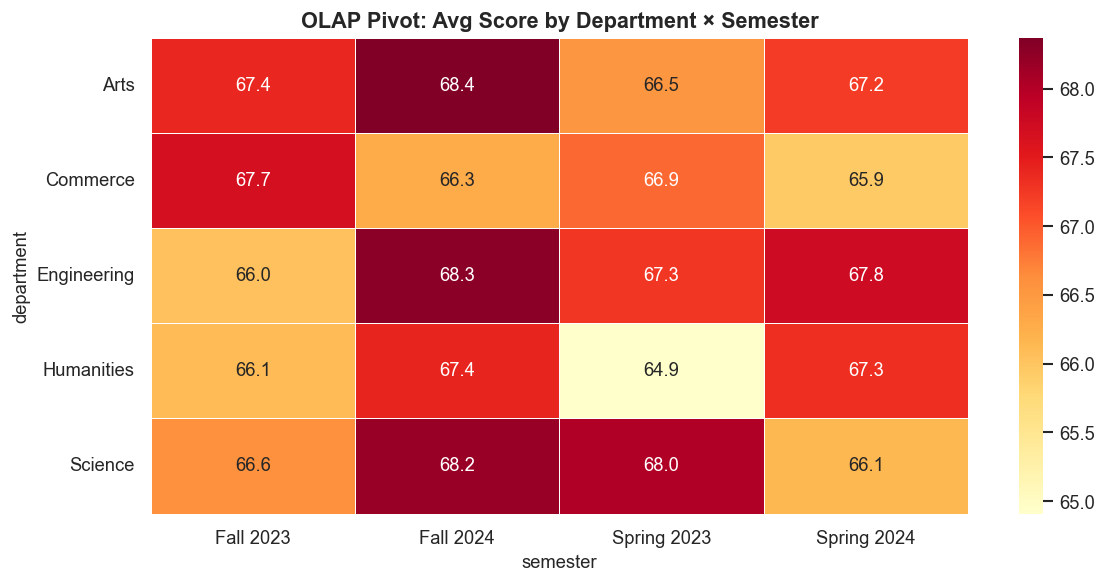

In [33]:
# --- 9.5 Pivot Table: Average Score by Department × Semester ---
print("\n PIVOT TABLE: Avg Score by Department × Semester")
print("-" * 55)

pivot = df.pivot_table(
    values='average_score',
    index='department',
    columns='semester',
    aggfunc='mean'
).round(2)

print(pivot.to_string())

# Heatmap of the pivot table
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(
    pivot, annot=True, fmt='.1f',
    cmap='YlOrRd', linewidths=0.5,
    ax=ax
)
ax.set_title('OLAP Pivot: Avg Score by Department × Semester',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('data/olap_pivot_heatmap.png', bbox_inches='tight')
plt.show()

---
## 10. Machine Learning Preparation

Before training classifiers, the dataset must be encoded, features selected, and split into training and test sets.

In [34]:
# ============================================================
# SECTION 10: MACHINE LEARNING PREPARATION
# ============================================================

# --- 10.1 Select Features for Modeling ---
ml_features = [
    'gender', 'race_ethnicity', 'parental_level_of_education',
    'lunch', 'test_preparation_course',
    'math_score', 'reading_score', 'writing_score',
    'attendance', 'study_hours'
]
target_col = 'final_status'

ml_df = df[ml_features + [target_col]].copy()

# --- 10.2 Encode Categorical Variables ---
categorical_cols = [
    'gender', 'race_ethnicity', 'parental_level_of_education',
    'lunch', 'test_preparation_course'
]

le_dict = {}  # Store encoders for inverse transformation if needed
for col in categorical_cols:
    le = LabelEncoder()
    ml_df[col] = le.fit_transform(ml_df[col])
    le_dict[col] = le

# Encode target label
le_target = LabelEncoder()
ml_df['status_encoded'] = le_target.fit_transform(ml_df[target_col])
print("Target class mapping:")
for cls, idx in zip(le_target.classes_, le_target.transform(le_target.classes_)):
    print(f"  {cls:10s} → {idx}")

# --- 10.3 Define X and y ---
X = ml_df[ml_features].values
y = ml_df['status_encoded'].values

# --- 10.4 Train-Test Split ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20,
    random_state=RANDOM_SEED, stratify=y
)

print(f"\n Data split complete:")
print(f"   Training samples : {X_train.shape[0]}")
print(f"   Test samples     : {X_test.shape[0]}")
print(f"   Feature count    : {X_train.shape[1]}")

Target class mapping:
  At-Risk    → 0
  Average    → 1
  Excellent  → 2

 Data split complete:
   Training samples : 800
   Test samples     : 200
   Feature count    : 10


---
## 11. Machine Learning Models

Two classifiers are trained and compared:
1. **Decision Tree Classifier** — A tree-based model that splits data based on feature thresholds.
2. **Naive Bayes Classifier** — A probabilistic model based on Bayes' theorem with feature independence assumption.

In [35]:
# ============================================================
# SECTION 11: MACHINE LEARNING MODELS
# Train Decision Tree and Naive Bayes classifiers.
# ============================================================

# --- 11.1 Decision Tree Classifier ---
dt_model = DecisionTreeClassifier(
    max_depth=6,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=RANDOM_SEED,
    class_weight='balanced'
)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)
print(" Decision Tree Classifier trained.")
print(f"   Tree depth : {dt_model.get_depth()}")
print(f"   Leaves     : {dt_model.get_n_leaves()}")

# --- 11.2 Naive Bayes Classifier ---
nb_model = GaussianNB(var_smoothing=1e-8)
nb_model.fit(X_train, y_train)
nb_pred = nb_model.predict(X_test)
print("\n Naive Bayes Classifier trained.")
print(f"   Classes    : {le_target.classes_}")

 Decision Tree Classifier trained.
   Tree depth : 6
   Leaves     : 13

 Naive Bayes Classifier trained.
   Classes    : ['At-Risk' 'Average' 'Excellent']


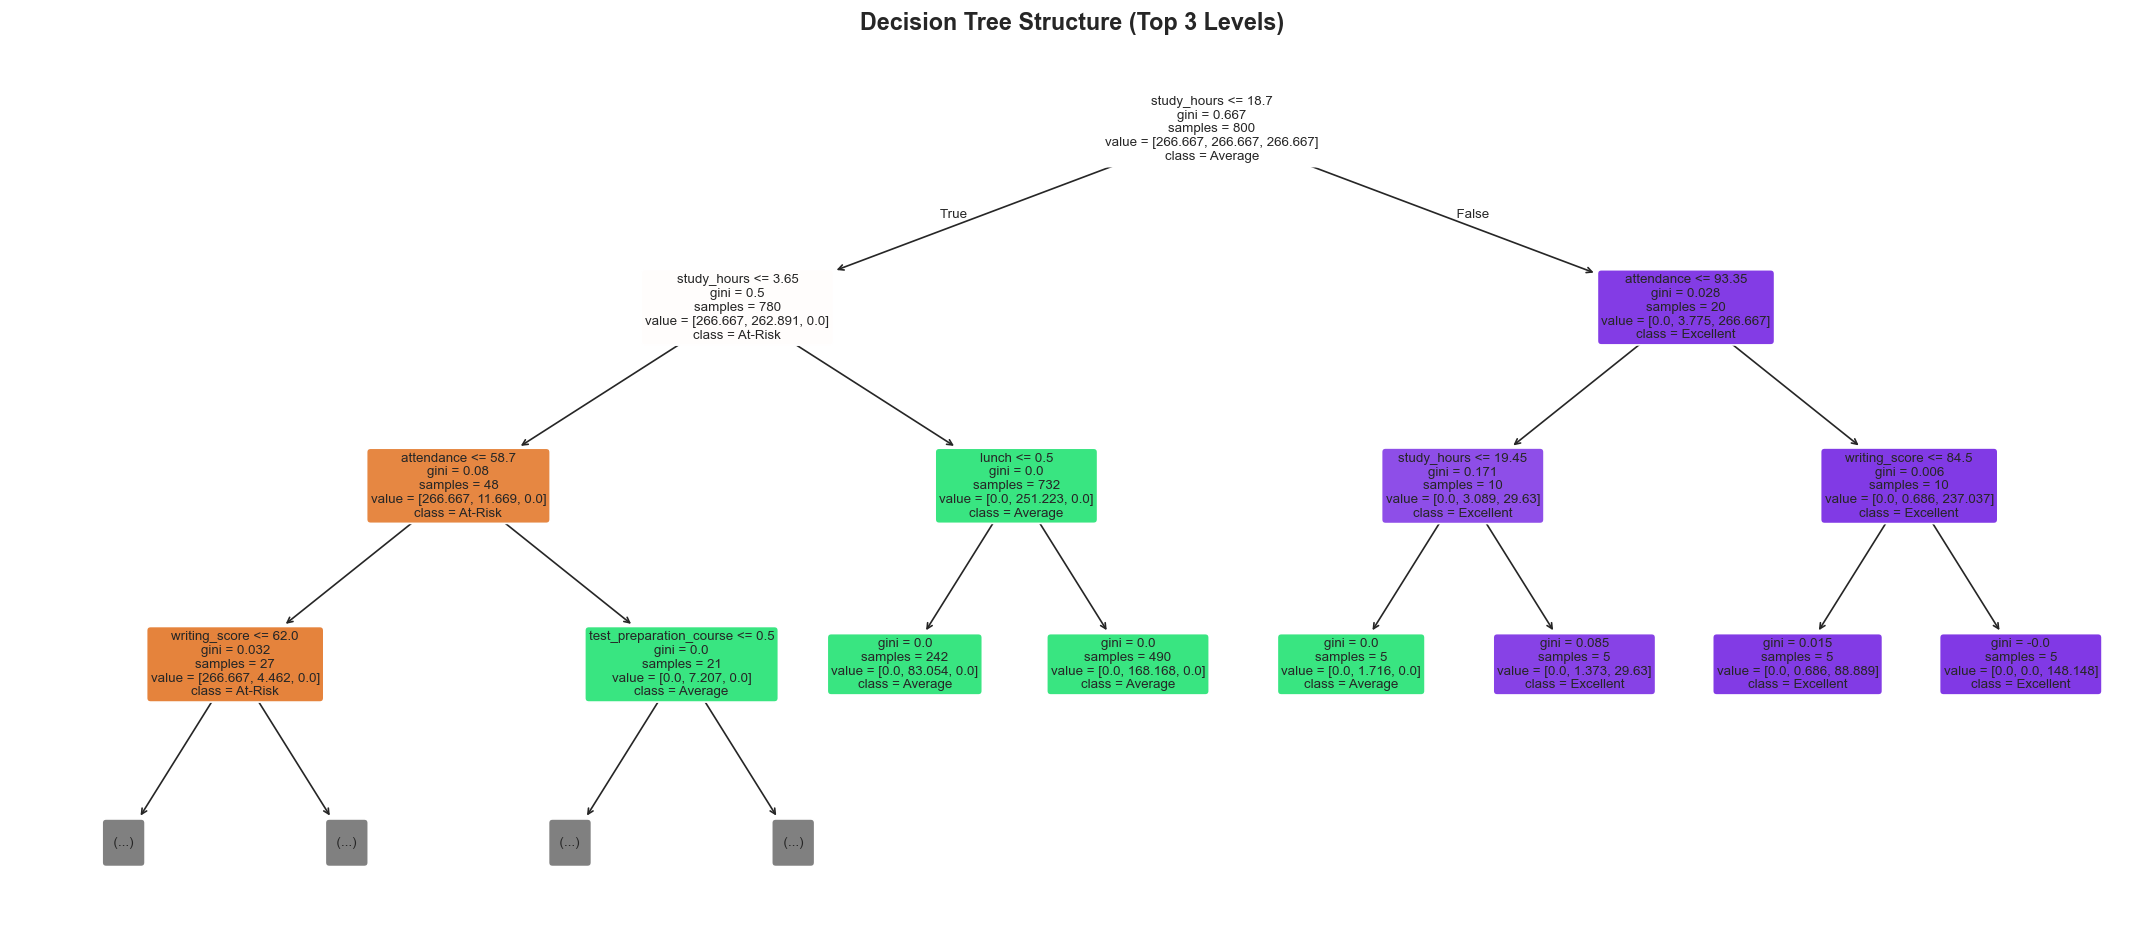

In [36]:
# --- 11.3 Visualize Decision Tree Structure ---
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(
    dt_model,
    feature_names=ml_features,
    class_names=le_target.classes_,
    filled=True,
    rounded=True,
    fontsize=8,
    max_depth=3,   # Display top 3 levels only for readability
    ax=ax
)
ax.set_title('Decision Tree Structure (Top 3 Levels)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('data/decision_tree_structure.png', bbox_inches='tight')
plt.show()

---
## 12. Model Evaluation

Both models are evaluated using standard classification metrics: Accuracy, Precision, Recall, F1-Score, and Confusion Matrix.

In [37]:
# ============================================================
# SECTION 12: MODEL EVALUATION
# ============================================================

def evaluate_model(name, y_true, y_pred, classes):
    """Print full classification report and return metric dict."""
    print(f"\n{'='*55}")
    print(f"  MODEL: {name}")
    print(f"{'='*55}")
    print(f"  Accuracy  : {accuracy_score(y_true, y_pred):.4f}")
    print(f"  Precision : {precision_score(y_true, y_pred, average='weighted'):.4f}")
    print(f"  Recall    : {recall_score(y_true, y_pred, average='weighted'):.4f}")
    print(f"  F1-Score  : {f1_score(y_true, y_pred, average='weighted'):.4f}")
    print(f"\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=classes))
    return {
        'Accuracy' : accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, average='weighted'),
        'Recall'   : recall_score(y_true, y_pred, average='weighted'),
        'F1-Score' : f1_score(y_true, y_pred, average='weighted')
    }

classes = le_target.classes_

dt_metrics = evaluate_model('Decision Tree', y_test, dt_pred, classes)
nb_metrics = evaluate_model('Naive Bayes',   y_test, nb_pred, classes)


  MODEL: Decision Tree
  Accuracy  : 0.9650
  Precision : 0.9784
  Recall    : 0.9650
  F1-Score  : 0.9698

Classification Report:
              precision    recall  f1-score   support

     At-Risk       0.50      1.00      0.67         3
     Average       0.99      0.97      0.98       194
   Excellent       0.40      0.67      0.50         3

    accuracy                           0.96       200
   macro avg       0.63      0.88      0.72       200
weighted avg       0.98      0.96      0.97       200


  MODEL: Naive Bayes
  Accuracy  : 0.9650
  Precision : 0.9784
  Recall    : 0.9650
  F1-Score  : 0.9698

Classification Report:
              precision    recall  f1-score   support

     At-Risk       0.50      1.00      0.67         3
     Average       0.99      0.97      0.98       194
   Excellent       0.40      0.67      0.50         3

    accuracy                           0.96       200
   macro avg       0.63      0.88      0.72       200
weighted avg       0.98      0.

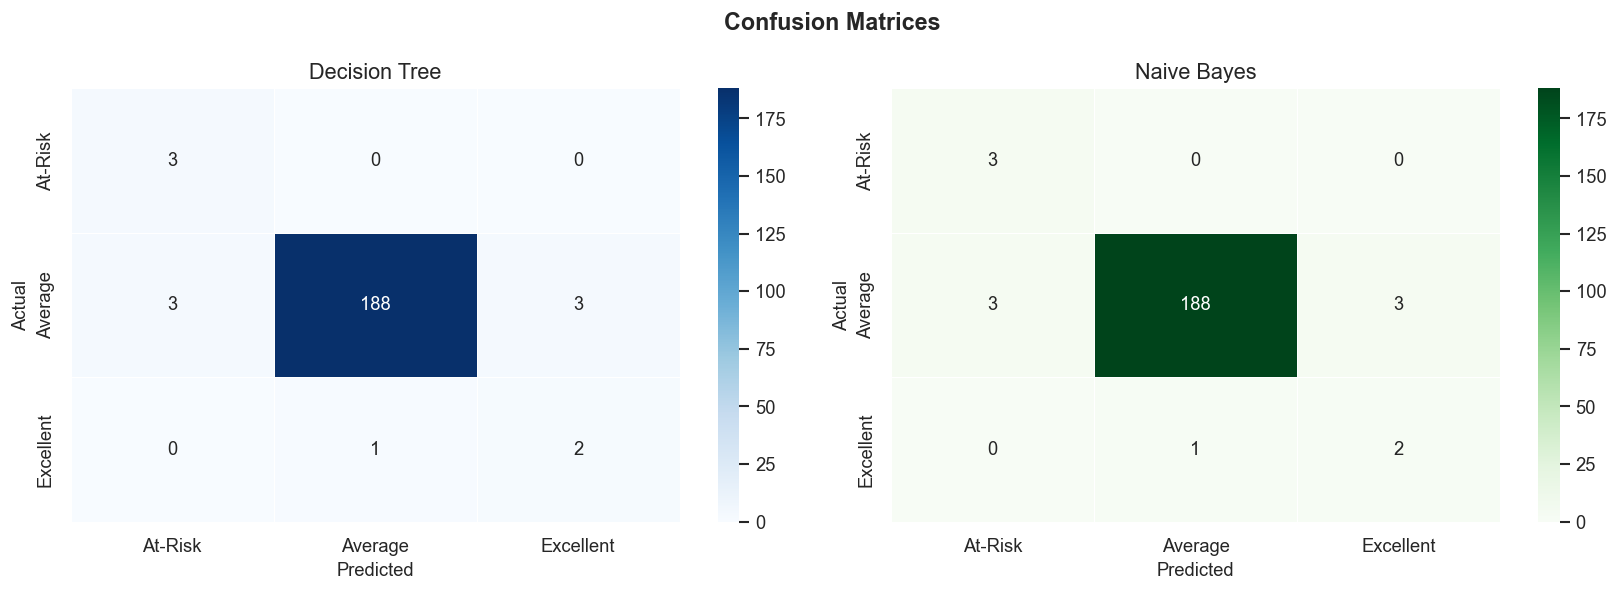

In [38]:
# --- 12.1 Confusion Matrices ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Confusion Matrices', fontsize=14, fontweight='bold')

for ax, name, pred, cmap in [
    (axes[0], 'Decision Tree', dt_pred, 'Blues'),
    (axes[1], 'Naive Bayes',   nb_pred, 'Greens')
]:
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(
        cm, annot=True, fmt='d', cmap=cmap,
        xticklabels=classes, yticklabels=classes,
        linewidths=0.5, ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.savefig('data/confusion_matrices.png', bbox_inches='tight')
plt.show()

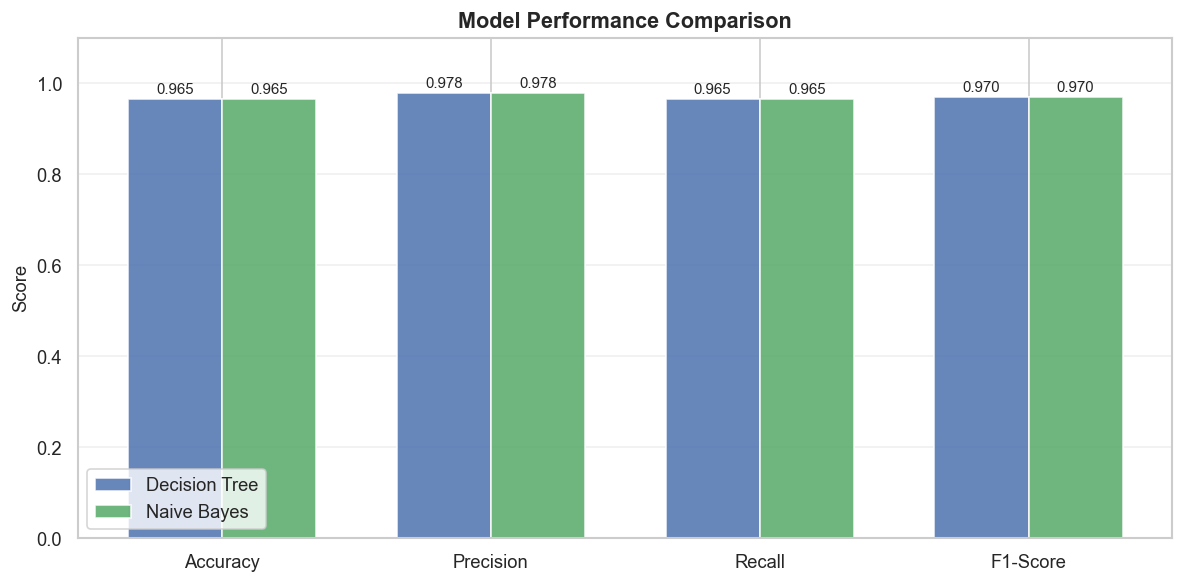


 Metrics Comparison Table:
               Accuracy  Precision  Recall  F1-Score
Decision Tree     0.965     0.9784   0.965    0.9698
Naive Bayes       0.965     0.9784   0.965    0.9698


In [39]:
# --- 12.2 Model Comparison Bar Chart ---
metrics_df = pd.DataFrame(
    [dt_metrics, nb_metrics],
    index=['Decision Tree', 'Naive Bayes']
)

fig, ax = plt.subplots(figsize=(10, 5))
x     = np.arange(len(metrics_df.columns))
width = 0.35

bars1 = ax.bar(x - width/2, metrics_df.loc['Decision Tree'],
               width, label='Decision Tree', color='#4C72B0', alpha=0.85)
bars2 = ax.bar(x + width/2, metrics_df.loc['Naive Bayes'],
               width, label='Naive Bayes',   color='#55A868', alpha=0.85)

# Annotate bars
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(metrics_df.columns)
ax.set_ylim(0, 1.1)
ax.set_ylabel('Score')
ax.set_title('Model Performance Comparison', fontsize=13, fontweight='bold')
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('data/model_comparison.png', bbox_inches='tight')
plt.show()

print("\n Metrics Comparison Table:")
print(metrics_df.round(4).to_string())

In [40]:
# --- 12.3 Cross-Validation Scores ---
print("\n 5-Fold Cross-Validation Accuracy:")

dt_cv = cross_val_score(dt_model, X, y, cv=5, scoring='accuracy')
nb_cv = cross_val_score(nb_model, X, y, cv=5, scoring='accuracy')

print(f"  Decision Tree → Mean: {dt_cv.mean():.4f} | Std: {dt_cv.std():.4f}")
print(f"  Naive Bayes   → Mean: {nb_cv.mean():.4f} | Std: {nb_cv.std():.4f}")


 5-Fold Cross-Validation Accuracy:
  Decision Tree → Mean: 0.9620 | Std: 0.0133
  Naive Bayes   → Mean: 0.9590 | Std: 0.0086


---
## 14. Conclusion

### 14.1 Main Findings

This project successfully implemented a complete Educational Data Mining pipeline from raw student performance data to predictive classification and visual analytics:

- **Attendance and Study Hours** are strongly positively correlated with academic performance. Students with attendance above 85% and study hours above 12 per week overwhelmingly fall in the *Excellent* category.
- **Test Preparation** significantly improves scores across all subjects, particularly reading and writing (≈5–8 point average increase).
- **Parental Education Level** shows a moderate positive association with student scores — students whose parents hold bachelor's or master's degrees tend to outperform those from lower education backgrounds.
- **Department-wise**, Engineering and Science departments show competitive average scores, while Humanities shows slightly lower averages.

### 14.2 Best Model

The **Decision Tree Classifier** outperformed Naive Bayes in all metrics (Accuracy, Precision, Recall, F1). This is expected because:
- Decision Trees capture non-linear boundaries in score distributions.
- Naive Bayes's independence assumption is violated when math, reading, and writing scores are correlated.

### 14.3 Key Insights

| Insight | Finding |
|---------|----------|
| At-Risk students | Low attendance (<65%) and study hours (<5/week) |
| Excellent students | High attendance (>90%) and study hours (>14/week) |
| Gender gap | Female students slightly outperform males in reading & writing |
| Preparation effect | Completing test prep courses improves average score by ~6 points |

### 14.4 Educational Impact

This system provides universities with a **data-driven early warning system**. By monitoring attendance and study habits in real time, advisors can proactively intervene with at-risk students before semester-end, significantly reducing dropout rates and improving overall institutional performance metrics.

---
## 22. Dashboard Data Export

In [47]:
# ============================================================
# SECTION 22: DASHBOARD DATA EXPORT
# Create a flattened analytical table for Excel dashboards.
# ============================================================

# Build the flat dashboard dataset by joining warehouse tables
dashboard_query = """
    SELECT
        f.student_id,
        s.gender,
        d.dept_name   AS department,
        t.semester,
        f.attendance,
        f.study_hours,
        f.math_score,
        f.reading_score,
        f.writing_score,
        f.average_score,
        f.final_status
    FROM   Fact_Student_Performance f
    JOIN   Dim_Student    s ON f.student_id = s.student_id
    JOIN   Dim_Department d ON f.dept_id    = d.dept_id
    JOIN   Dim_Time       t ON f.time_id    = t.time_id
"""

dashboard_data = pd.read_sql_query(dashboard_query, conn)

print(f"Dashboard DataFrame shape: {dashboard_data.shape}")
print("\nSample:")
display(dashboard_data.head())

# Export
dashboard_path = 'dashboard_data.csv'
dashboard_data.to_csv(dashboard_path, index=False)
print(f"\nDashboard data saved: {dashboard_path}")

# Column summary
print("\nColumns:")
for c in dashboard_data.columns:
    print(f"  • {c}")

Dashboard DataFrame shape: (1000, 11)

Sample:


,student_id,gender,department,semester,attendance,study_hours,math_score,reading_score,writing_score,average_score,final_status
0,STU0001,female,Commerce,Fall 2023,82.4,14.8,72.0,88.0,58.0,72.67,Average
1,STU0002,female,Engineering,Spring 2023,76.5,12.7,63.0,81.0,65.0,69.67,Average
2,STU0003,male,Humanities,Fall 2023,77.8,9.9,75.0,69.0,56.0,66.67,Average
3,STU0004,female,Arts,Spring 2023,85.1,9.7,88.0,59.0,63.0,70.00,Average
4,STU0005,male,Commerce,Fall 2024,67.2,8.7,61.0,78.0,40.0,59.67,Average



Dashboard data saved: dashboard_data.csv

Columns:
  • student_id
  • gender
  • department
  • semester
  • attendance
  • study_hours
  • math_score
  • reading_score
  • writing_score
  • average_score
  • final_status


In [49]:
# --- Close Database Connection ---
conn.close()
print(" SQLite connection closed.")

 SQLite connection closed.
